# 10 — Interpretabilidad del Modelo
## Pipeline CAD-TBX11K | Diagnóstico Asistido por Computador en Tuberculosis

Este notebook explica el **modelo final seleccionado en el notebook 08: XGBoost** con
selector `SelectKBest` (Mutual Information, 300 features). No evalúa rendimiento: las
métricas siguen siendo las OOF del notebook 09.

### Alcance
- SHAP con `TreeExplainer` sobre el XGBoost real (multiclase, 3 clases).
- Importancia global y por clase (`health`, `sick`, `tb`).
- Importancia por familia de características.
- Explicaciones individuales OOF con el modelo del fold correspondiente.
- Atribución espacial por oclusión y solape con las cajas de lesión.

Los valores SHAP son atribuciones al **output del modelo** (margen/log-odds para
`multi:softprob`), no probabilidades. El eje de clase sigue `clf.classes_` = `[0, 1, 2]`.


## 0. Configuración del entorno


In [1]:
# Se configura el path del proyecto y se importan las librerías necesarias.
# Referencias:
#   SHAP TreeExplainer: https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html
#   XGBoost: https://xgboost.readthedocs.io/en/stable/

import sys, os, warnings, json, tempfile
warnings.filterwarnings('ignore')

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import cv2
import joblib
import shap

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import balanced_accuracy_score, recall_score

_CWD = os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(_CWD, '..')) if os.path.basename(_CWD) == 'notebooks' else _CWD
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.selection import build_selector
from src.preprocessing import preprocess
from src.features import extract_features
from src.features import model_feature_columns
from src.visualization import set_publication_style

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CLASS_NAMES = ['health', 'sick', 'tb']
DATA_DIR    = Path(PROJECT_ROOT) / 'data'
MODELS_DIR  = Path(PROJECT_ROOT) / 'models'
REPORTS_DIR = Path(PROJECT_ROOT) / 'reports'
REPORTS_DIR.mkdir(exist_ok=True)

set_publication_style()
print('Entorno configurado correctamente.')
print(f'SHAP {shap.__version__}')


Entorno configurado correctamente.
SHAP 0.54.1


## 1. Carga y verificación de artefactos


In [2]:
# Se comprueban el modelo final, el manifiesto, la selección del 06 y las predicciones OOF.

ARCHIVOS = [
    MODELS_DIR / '08_xgboost.joblib',
    MODELS_DIR / '08_manifest.json',
    DATA_DIR / '06_seleccion.json',
    DATA_DIR / '06_selected_feature_names.json',
    DATA_DIR / 'X_full.npy',
    DATA_DIR / 'y_full.npy',
    DATA_DIR / '08_oof_predicciones.csv',
    DATA_DIR / '08_oof_scores.npz',
    DATA_DIR / '08_cv_por_fold.csv',
    DATA_DIR / 'features_tbx11k.csv',
]
for archivo in ARCHIVOS:
    if not archivo.exists():
        raise FileNotFoundError(f'No se encontró {archivo}. Ejecuta primero la cadena 05–09.')

modelo = joblib.load(MODELS_DIR / '08_xgboost.joblib')
selector = modelo.named_steps['selector']
clf = modelo.named_steps['clf']
scaler = modelo.named_steps.get('scaler', None)

print('Pipeline :', [paso[0] for paso in modelo.steps])
print('Selector :', type(selector).__name__)
print('Clasificador:', type(clf).__name__)
print('  classes:', clf.classes_)
print('  objective:', clf.get_params().get('objective'))
print('  feature_importances_:', clf.feature_importances_.shape)
print('  scaler:', type(scaler).__name__ if scaler is not None else 'None')

with open(MODELS_DIR / '08_manifest.json', encoding='utf-8') as f:
    manifest = json.load(f)
print()
print('Modelo seleccionado en 08:', manifest['seleccionado_cv'])
print('Selector en 08:', manifest['selector'])
if manifest['seleccionado_cv'] != 'XGBoost':
    print('ADVERTENCIA: el manifiesto no corresponde a XGBoost; revisar el 08.')

# Nombres de las features seleccionadas en el orden de columnas del selector.
feat_cols = model_feature_columns(
    pd.read_csv(DATA_DIR / 'features_tbx11k.csv', nrows=0)
)
sel_idx = selector.get_support(indices=True)
pipeline_names = [feat_cols[i] for i in sel_idx]

with open(DATA_DIR / '06_selected_feature_names.json', encoding='utf-8') as f:
    names_06 = json.load(f)
mismo_conjunto = set(pipeline_names) == set(names_06)
if not mismo_conjunto:
    print('ADVERTENCIA: el conjunto de features del pipeline difiere del 06; '
          'se usan las del pipeline final para explicar el modelo.')
print()
print(f'Features seleccionadas: {len(pipeline_names)}')
estado = "sí" if mismo_conjunto else "no"
print(f'Mismo conjunto que 06: {estado} '
      '(el 06 las guarda en orden de importancia; aquí en orden de columna).')

X_full = np.load(DATA_DIR / 'X_full.npy')
y_full = np.load(DATA_DIR / 'y_full.npy')
oof = pd.read_csv(DATA_DIR / '08_oof_predicciones.csv')
scores = np.load(DATA_DIR / '08_oof_scores.npz')
fold_params = pd.read_csv(DATA_DIR / '08_cv_por_fold.csv')

if not np.array_equal(oof['y_true'].to_numpy(), y_full):
    raise ValueError('y_true del OOF no coincide con y_full.')

print()
print(f'X_full: {X_full.shape} | y_full: {y_full.shape}')
print(f'OOF XGBoost: BalAcc={balanced_accuracy_score(y_full, oof["XGBoost"]):.4f} | '
      f'Recall tb={recall_score(y_full, oof["XGBoost"], labels=[2], average=None)[0]:.4f}')
print('Parámetros XGBoost por fold:')
print(fold_params[fold_params['Modelo'] == 'XGBoost'][['Fold', 'Mejores params']].to_string(index=False))


Pipeline : ['selector', 'clf']
Selector : RFTopNSelector
Clasificador: XGBClassifier
  classes: [0 1 2]
  objective: multi:softprob
  feature_importances_: (300,)
  scaler: None

Modelo seleccionado en 08: Logistic Regression
Selector en 08: {'metodo': 'RF', 'n_features': 300}
ADVERTENCIA: el manifiesto no corresponde a XGBoost; revisar el 08.

Features seleccionadas: 300
Mismo conjunto que 06: sí (el 06 las guarda en orden de importancia; aquí en orden de columna).

X_full: (8256, 1832) | y_full: (8256,)
OOF XGBoost: BalAcc=0.8690 | Recall tb=0.7550
Parámetros XGBoost por fold:
 Fold                                   Mejores params
    1 {"clf__learning_rate": 0.1, "clf__max_depth": 2}
    2 {"clf__learning_rate": 0.1, "clf__max_depth": 2}
    3 {"clf__learning_rate": 0.1, "clf__max_depth": 2}
    4 {"clf__learning_rate": 0.1, "clf__max_depth": 2}
    5 {"clf__learning_rate": 0.1, "clf__max_depth": 2}


## 2. Preparación del espacio de interpretación


In [3]:
# Muestra estratificada para SHAP y agrupación de features por familia.
# TreeExplainer no necesita escalado en este pipeline: el XGBoost final no tiene scaler.

N_POR_CLASE = 500
rng = np.random.RandomState(RANDOM_STATE)
idx = []
for clase in np.unique(y_full):
    idx_clase = np.where(y_full == clase)[0]
    idx.extend(rng.choice(idx_clase, size=N_POR_CLASE, replace=False))
idx = np.array(idx)

X_sample = X_full[idx]
y_sample = y_full[idx]
X_sample_sel = selector.transform(X_sample)

feature_names = pipeline_names


def grupo_feature(nombre):
    if nombre.startswith('hog_'):
        return 'HOG'
    if nombre.startswith('phog_'):
        return 'PHOG'
    if nombre.startswith('gabor_'):
        return 'Gabor'
    if nombre.startswith('lbp_'):
        return 'LBP'
    if nombre.startswith('glcm_'):
        return 'GLCM'
    if nombre in ('mean', 'std', 'contrast', 'entropy'):
        return 'Intensidad global'
    if nombre[:2] in ('SI', 'SD', 'MI', 'MD', 'II', 'ID'):
        return 'Intensidad regional'
    return 'Otra'


GRUPOS = ['HOG', 'PHOG', 'GLCM', 'LBP', 'Gabor', 'Intensidad global', 'Intensidad regional']
grupos_por_feature = [grupo_feature(n) for n in feature_names]
conteo_grupos = pd.Series(grupos_por_feature).value_counts().reindex(GRUPOS).fillna(0).astype(int)

print('Composición de las features seleccionadas:')
print(conteo_grupos.to_string())

explainer = shap.TreeExplainer(clf)
sv = explainer(X_sample_sel)

print()
print(f'SHAP values: {sv.values.shape} (muestras, features, clases)')
print(f'base_values: {sv.base_values.shape}')
print('Eje de clase:', dict(enumerate(CLASS_NAMES)))
print('Salida explicada: margen/log-odds del XGBoost (multi:softprob), no probabilidad.')


Composición de las features seleccionadas:
HOG                    249
PHOG                     0
GLCM                     8
LBP                     12
Gabor                   31
Intensidad global        0
Intensidad regional      0

SHAP values: (1500, 300, 3) (muestras, features, clases)
base_values: (1500, 3)
Eje de clase: {0: 'health', 1: 'sick', 2: 'tb'}
Salida explicada: margen/log-odds del XGBoost (multi:softprob), no probabilidad.


## 3. SHAP global


Top-20 features por |SHAP| global:
               feature  mean_abs_shap grupo
                lbp_25       0.189028   LBP
                lbp_12       0.176692   LBP
    gabor_f0.4_t0_mean       0.149567 Gabor
  glcm_homogeneity_std       0.123911  GLCM
                lbp_13       0.104198   LBP
    gabor_f0.4_t90_std       0.100469 Gabor
    gabor_f0.2_t0_mean       0.084012 Gabor
 glcm_homogeneity_mean       0.078989  GLCM
   gabor_f0.3_t45_mean       0.078755 Gabor
              hog_1657       0.077362   HOG
              hog_1177       0.077079   HOG
               hog_774       0.075094   HOG
    gabor_f0.3_t0_mean       0.070252 Gabor
               hog_461       0.066289   HOG
   gabor_f0.4_t90_mean       0.066260 Gabor
   gabor_f0.4_t135_std       0.065043 Gabor
              hog_1316       0.064421   HOG
               hog_856       0.063788   HOG
glcm_dissimilarity_std       0.063641  GLCM
              hog_1276       0.061489   HOG

Solapamiento top-20 SHAP / gain: 10/20


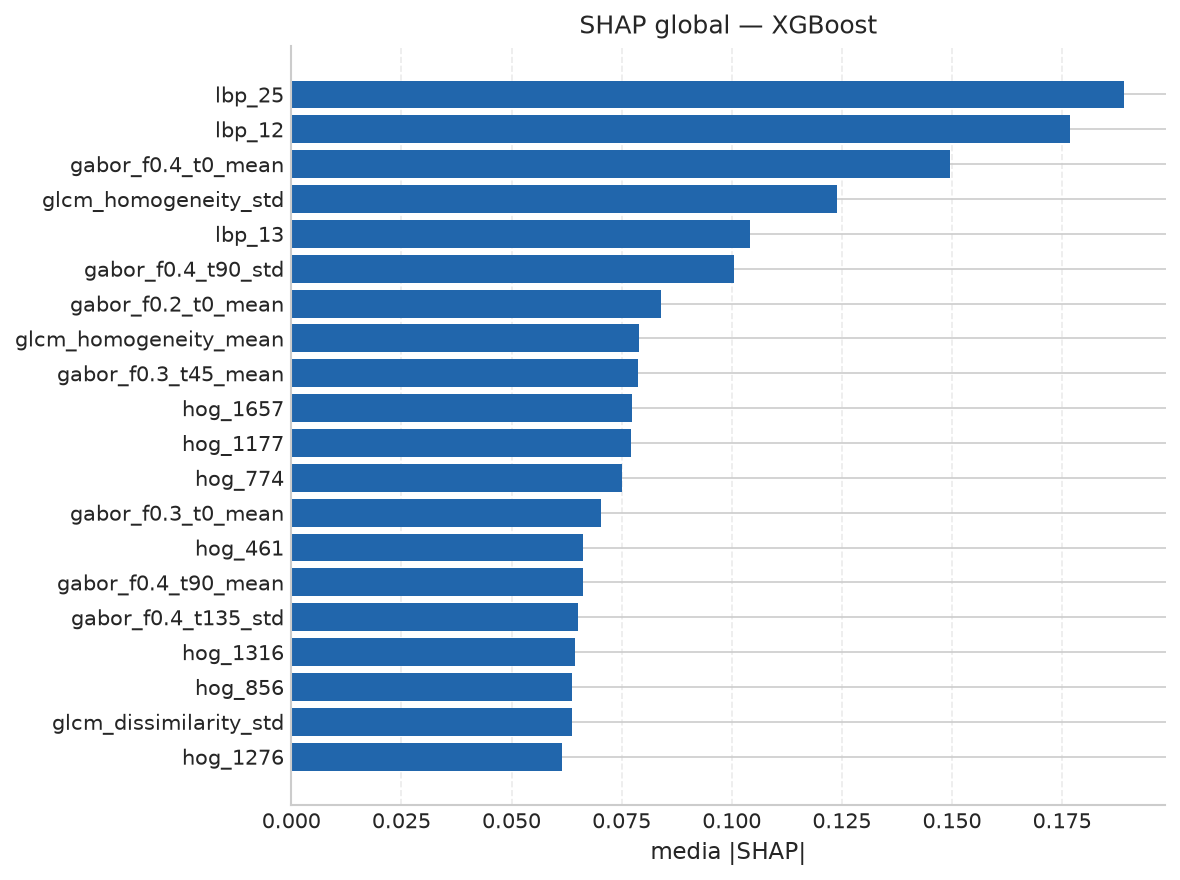

In [4]:
# Importancia global: media de |SHAP| sobre muestras y clases.
# Control de coherencia con la importancia nativa del XGBoost (gain).
# No es una validación independiente: ambos describen el mismo modelo.

abs_sv = np.abs(sv.values)
imp_global = abs_sv.mean(axis=(0, 2))
top = np.argsort(imp_global)[::-1][:20]

tabla = pd.DataFrame({
    'feature': [feature_names[i] for i in top],
    'mean_abs_shap': imp_global[top],
    'grupo': [grupo_feature(feature_names[i]) for i in top],
})
print('Top-20 features por |SHAP| global:')
print(tabla.round(6).to_string(index=False))

top_shap = set(top)
top_gain = set(np.argsort(clf.feature_importances_)[::-1][:20])
print()
print(f'Solapamiento top-20 SHAP / gain: {len(top_shap & top_gain)}/20')

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(tabla['feature'][::-1], tabla['mean_abs_shap'][::-1], color='#2166AC')
ax.set_xlabel('media |SHAP|', fontsize=11)
ax.set_title('SHAP global — XGBoost', fontsize=12)
ax.grid(True, axis='x', linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()


## 4. SHAP por clase



--- health ---
              feature  mean_abs_shap grupo
               lbp_12       0.454884   LBP
               lbp_25       0.311773   LBP
   gabor_f0.4_t90_std       0.243604 Gabor
             hog_1657       0.215127   HOG
  gabor_f0.4_t135_std       0.190115 Gabor
              hog_856       0.184498   HOG
             hog_1276       0.180197   HOG
glcm_homogeneity_mean       0.179048  GLCM
  gabor_f0.4_t90_mean       0.175550 Gabor
              hog_774       0.166702   HOG
             hog_1177       0.162532   HOG
              hog_828       0.158751   HOG
  gabor_f0.3_t45_mean       0.148966 Gabor
              hog_370       0.129409   HOG
             hog_1116       0.119318   HOG

--- sick ---
               feature  mean_abs_shap grupo
  glcm_homogeneity_std       0.293656  GLCM
    gabor_f0.2_t0_mean       0.193154 Gabor
glcm_dissimilarity_std       0.170671  GLCM
    gabor_f0.4_t0_mean       0.156470 Gabor
     gabor_f0.1_t0_std       0.137254 Gabor
               hog

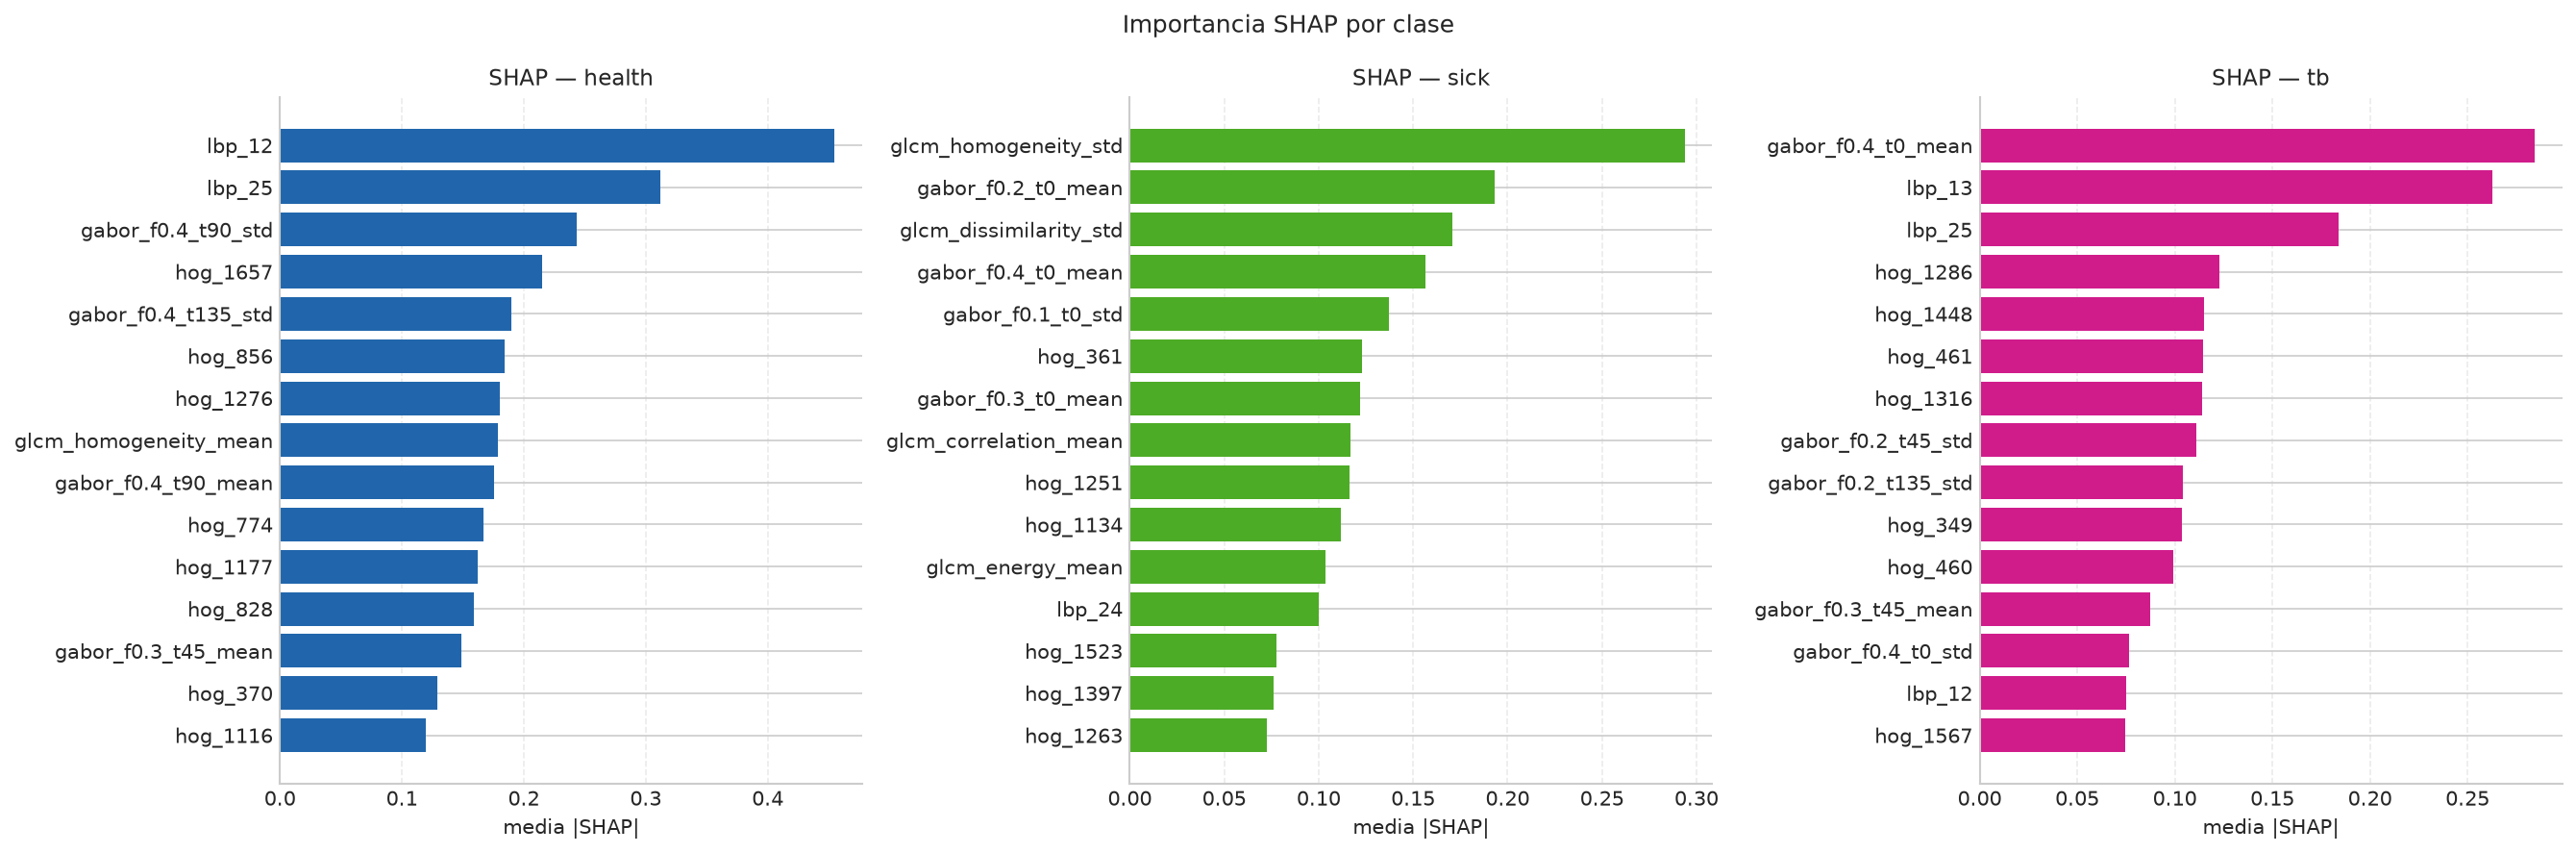

In [5]:
# Importancia por clase: media de |SHAP| sobre las muestras para cada clase.
# Permite comparar qué features sostienen health, sick y tb.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, c in zip(axes, range(len(CLASS_NAMES))):
    imp = abs_sv[:, :, c].mean(axis=0)
    top_c = np.argsort(imp)[::-1][:15]

    tabla_c = pd.DataFrame({
        'feature': [feature_names[i] for i in top_c],
        'mean_abs_shap': imp[top_c],
        'grupo': [grupo_feature(feature_names[i]) for i in top_c],
    })
    print()
    print(f'--- {CLASS_NAMES[c]} ---')
    print(tabla_c.round(6).to_string(index=False))

    ax.barh(tabla_c['feature'][::-1], tabla_c['mean_abs_shap'][::-1],
            color={'health': '#2166AC', 'sick': '#4DAC26', 'tb': '#D01C8B'}[CLASS_NAMES[c]])
    ax.set_title(f'SHAP — {CLASS_NAMES[c]}', fontsize=11)
    ax.set_xlabel('media |SHAP|', fontsize=10)
    ax.grid(True, axis='x', linestyle='--', alpha=0.4)

fig.suptitle('Importancia SHAP por clase', fontsize=12)
fig.tight_layout()
plt.show()


## 5. Importancia por familia de características


Importancia media por feature y familia:
Clase                  health      sick        tb
Grupo                                            
HOG                  0.021208  0.012966  0.012128
PHOG                      NaN       NaN       NaN
GLCM                 0.039195  0.093845  0.023227
LBP                  0.072280  0.021486  0.060697
Gabor                0.035672  0.032260  0.035161
Intensidad global         NaN       NaN       NaN
Intensidad regional       NaN       NaN       NaN


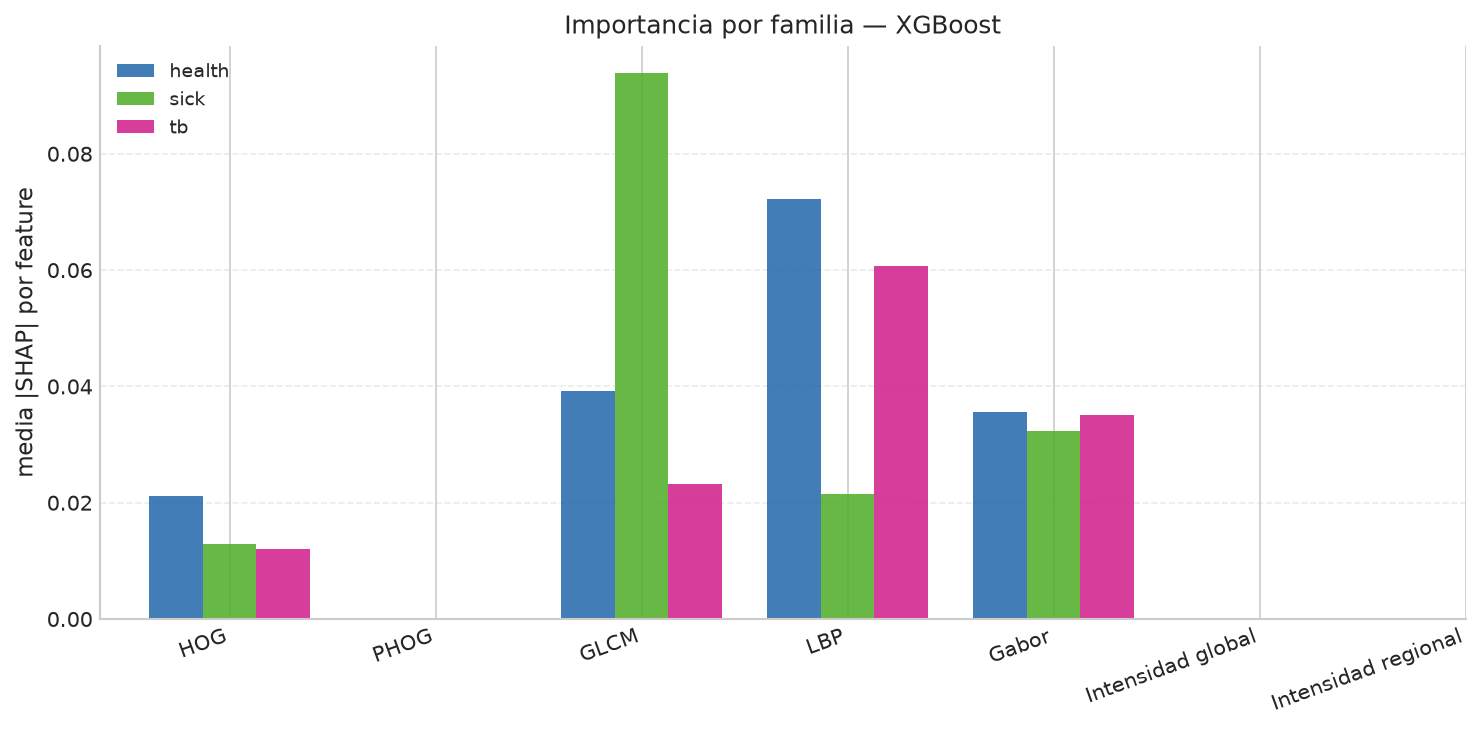

In [6]:
# Media de |SHAP| por feature dentro de cada familia, para comparar familias con
# distinto número de columnas sin que las más numerosas dominen por conteo.

def importancia_grupo(imp_vec):
    filas = []
    for grupo in GRUPOS:
        idx_grupo = [i for i, g in enumerate(grupos_por_feature) if g == grupo]
        if not idx_grupo:
            continue
        filas.append({
            'Grupo': grupo,
            'n_features': len(idx_grupo),
            '%_features': 100 * len(idx_grupo) / len(feature_names),
            'media_por_feature': float(np.mean(imp_vec[idx_grupo])),
            'total_grupo': float(np.sum(imp_vec[idx_grupo])),
        })
    return pd.DataFrame(filas)


tablas = []
for c, clase in enumerate(CLASS_NAMES):
    df_clase = importancia_grupo(abs_sv[:, :, c].mean(axis=0))
    df_clase['Clase'] = clase
    tablas.append(df_clase)

tabla_grupos = pd.concat(tablas, ignore_index=True)
print('Importancia media por feature y familia:')
print(tabla_grupos.pivot(index='Grupo', columns='Clase', values='media_por_feature')
      .reindex(GRUPOS).round(6).to_string())

pivote = tabla_grupos.pivot(index='Grupo', columns='Clase', values='media_por_feature').reindex(GRUPOS)
x = np.arange(len(pivote.index))
ancho = 0.26
fig, ax = plt.subplots(figsize=(10, 5))
for k, clase in enumerate(CLASS_NAMES):
    ax.bar(x + (k - 1) * ancho, pivote[clase], ancho, label=clase,
           color={'health': '#2166AC', 'sick': '#4DAC26', 'tb': '#D01C8B'}[clase],
           alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(pivote.index, rotation=20, ha='right')
ax.set_ylabel('media |SHAP| por feature', fontsize=11)
ax.set_title('Importancia por familia — XGBoost', fontsize=12)
ax.legend(fontsize=9)
ax.grid(True, axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()


## 6. Explicaciones individuales OOF


In [7]:
# Para explicar un error OOF se reconstruye el modelo del fold que generó esa predicción:
# mismo selector MI, mismos parámetros y mismo sample_weight balanceado que el 08.

with open(DATA_DIR / '06_seleccion.json', encoding='utf-8') as f:
    seleccion = json.load(f)
METHOD_SEL = seleccion['metodo']
N_SEL = int(seleccion['n_features'])
print(f'Selector del 06: {METHOD_SEL}, N={N_SEL}')

params_por_fold = {
    int(fila['Fold']): json.loads(fila['Mejores params'])
    for _, fila in fold_params[fold_params['Modelo'] == 'XGBoost'].iterrows()
}

cv_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv_outer.split(X_full, y_full))
fold_of_index = {}
for fold, (_, va_idx) in enumerate(folds, start=1):
    for i in va_idx:
        fold_of_index[int(i)] = fold

fold_cache = {}


def obtener_modelo_fold(fold):
    """Reconstruye el XGBoost del fold con selector MI y sample_weight balanceado."""
    if fold in fold_cache:
        return fold_cache[fold]

    tr_idx, va_idx = folds[fold - 1]
    params = params_por_fold[fold]

    selector_f = build_selector(METHOD_SEL, N_SEL, random_state=RANDOM_STATE, n_jobs=-1)
    selector_f.fit(X_full[tr_idx], y_full[tr_idx])
    X_tr = selector_f.transform(X_full[tr_idx])

    clf_f = XGBClassifier(
        n_estimators=300, max_depth=params.get('clf__max_depth', 6),
        learning_rate=params.get('clf__learning_rate', 0.1),
        subsample=0.8, colsample_bytree=0.8,
        objective='multi:softprob', num_class=len(CLASS_NAMES),
        eval_metric='mlogloss', tree_method='hist',
        n_jobs=1, random_state=RANDOM_STATE,
    )
    clf_f.fit(X_tr, y_full[tr_idx],
              sample_weight=compute_sample_weight('balanced', y_full[tr_idx]))

    fold_cache[fold] = (selector_f, clf_f, va_idx)
    return fold_cache[fold]


y_true = oof['y_true'].to_numpy()
pred_xgb = oof['XGBoost'].to_numpy()
casos = {
    'tb correcto': np.where((y_true == 2) & (pred_xgb == 2))[0],
    'tb falso negativo': np.where((y_true == 2) & (pred_xgb != 2))[0],
    'tb falso positivo': np.where((y_true != 2) & (pred_xgb == 2))[0],
}
seleccion_casos = {nombre: int(rng.choice(indices)) for nombre, indices in casos.items()}

for etiqueta, idx_ejemplo in seleccion_casos.items():
    fold = fold_of_index[idx_ejemplo]
    selector_f, clf_f, va_idx = obtener_modelo_fold(fold)

    x_sel = selector_f.transform(X_full[[idx_ejemplo]])
    pred_fold = int(clf_f.predict(x_sel)[0])
    nombres_fold = [feat_cols[i] for i in selector_f.get_support(indices=True)]
    explainer_f = shap.TreeExplainer(clf_f)
    sv_i = explainer_f(x_sel)

    print('=' * 72)
    print(f'{etiqueta} | índice={idx_ejemplo} | fold={fold}')
    print(f'  real={CLASS_NAMES[int(y_true[idx_ejemplo])]} | '
          f'OOF={CLASS_NAMES[int(pred_xgb[idx_ejemplo])]} | fold={CLASS_NAMES[pred_fold]}')
    if pred_fold != int(pred_xgb[idx_ejemplo]):
        print('  ADVERTENCIA: la predicción reconstruida no coincide con la OOF.')

    for clase in {int(y_true[idx_ejemplo]), int(pred_xgb[idx_ejemplo])}:
        contrib = sv_i.values[0, :, clase]
        top_ej = np.argsort(np.abs(contrib))[::-1][:8]
        tabla_ej = pd.DataFrame({
            'feature': [nombres_fold[i] for i in top_ej],
            'shap': contrib[top_ej],
            'valor_feature': x_sel[0, top_ej],
        })
        print(f'  Clase {CLASS_NAMES[clase]}:')
        print(tabla_ej.round(4).to_string(index=False))


Selector del 06: RF, N=300
tb correcto | índice=8140 | fold=3
  real=tb | OOF=tb | fold=tb
  Clase tb:
             feature    shap  valor_feature
 gabor_f0.2_t135_std  0.4732      17.341999
            hog_1586  0.2583       0.439300
             hog_461  0.2256       0.127700
  gabor_f0.4_t0_mean -0.1938       2.047500
  gabor_f0.2_t45_std  0.1851      17.527700
            hog_1097  0.1598       0.314900
             hog_568  0.1340       0.249200
gabor_f0.1_t135_mean  0.1225     243.331497
tb falso negativo | índice=7755 | fold=1
  real=tb | OOF=sick | fold=sick
  Clase sick:
               feature    shap  valor_feature
              hog_1240  0.2896       0.002600
  glcm_homogeneity_std -0.2741       0.045800
              hog_1251  0.2108       0.171300
glcm_dissimilarity_std -0.1682       0.196900
                lbp_25  0.1381       0.091600
              hog_1006  0.1378       0.002900
               hog_142  0.1363       0.028000
    gabor_f0.2_t0_mean -0.1306      26.155199

## 7. Atribución espacial y cajas de lesión


Imágenes de TB con cajas: 169 | TB correctas con caja: 126


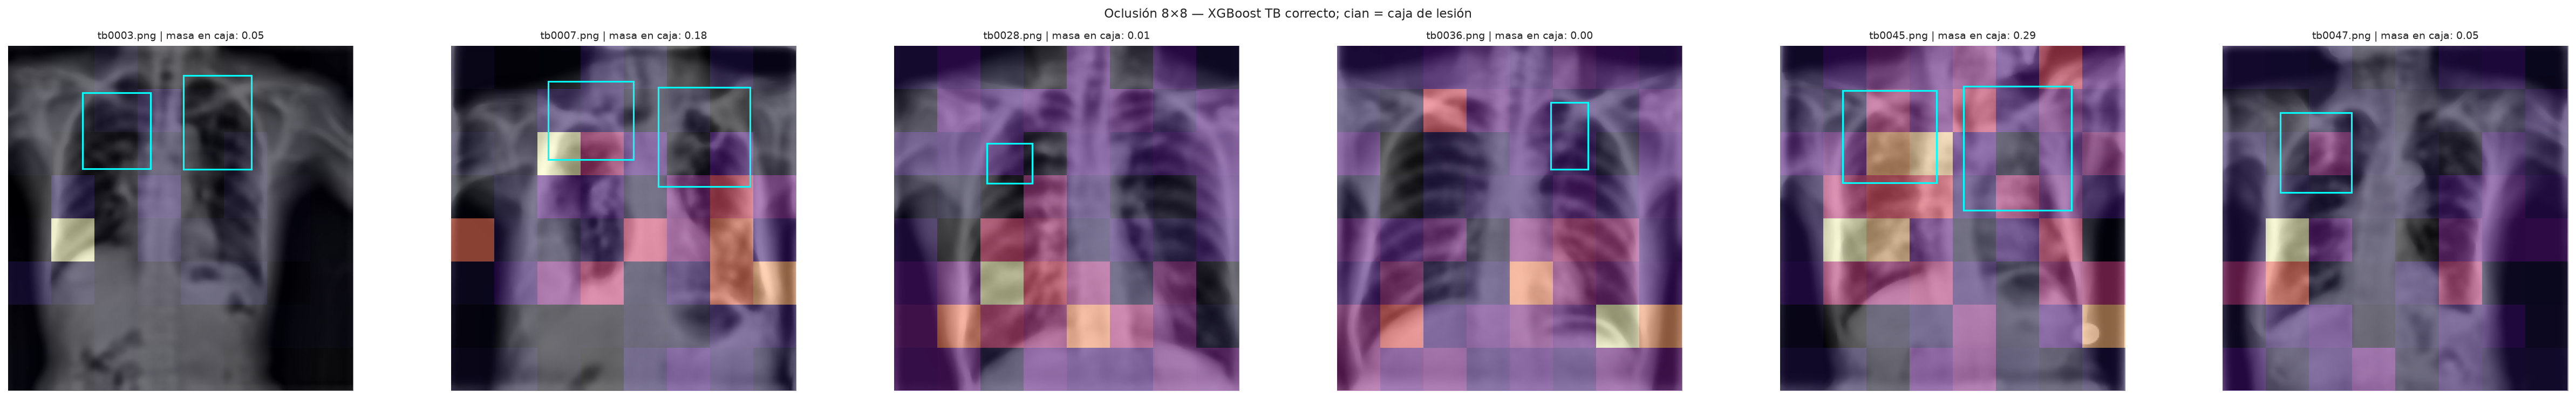

In [8]:
# Mapas de oclusión 8x8 sobre el XGBoost final: se tapa cada celda, se reextrae el
# vector de features del esquema y se mide la caída de la probabilidad de TB.
# Se comparan con las cajas de lesión anotadas de TBX11K.

coco_path = Path(PROJECT_ROOT) / 'data' / 'TBX11K' / 'annotations' / 'json' / 'TBX11K_trainval.json'
if not coco_path.exists():
    raise FileNotFoundError(f'No se encontró {coco_path}')

with open(coco_path, encoding='utf-8') as f:
    coco = json.load(f)

meta = pd.read_csv(DATA_DIR / 'full_meta.csv')
basename_to_idx = {Path(p).name: i for i, p in enumerate(meta['image_path'])}
imagenes_coco = {img['id']: img['file_name'] for img in coco['images']}
cat_tb = [c['id'] for c in coco['categories']
          if c['name'].lower() in ('tb', 'tuberculosis')]
cat_tb = cat_tb[0] if cat_tb else 2

cajas = {}
for ann in coco['annotations']:
    if ann.get('category_id') != cat_tb:
        continue
    file_name = imagenes_coco.get(ann['image_id'])
    if file_name is None:
        continue
    idx = basename_to_idx.get(Path(file_name).name)
    if idx is None:
        continue
    path = meta.loc[idx, 'image_path']
    cajas.setdefault(path, []).append(tuple(float(v) for v in ann['bbox']))

mask_tb = (oof['y_true'] == 2) & (oof['XGBoost'] == 2)
paths_tb_ok = set(meta.loc[mask_tb.to_numpy(), 'image_path'])
candidatos = sorted(set(cajas) & paths_tb_ok)
print(f'Imágenes de TB con cajas: {len(cajas)} | TB correctas con caja: {len(candidatos)}')
if not candidatos:
    raise ValueError('No hay imágenes de TB correctas con caja.')

ejemplos = candidatos[:6]
feat_cols = model_feature_columns(
    pd.read_csv(DATA_DIR / 'features_tbx11k.csv', nrows=0)
)

GRID = 8
fig, axes = plt.subplots(1, len(ejemplos), figsize=(5.5 * len(ejemplos), 5))
if len(ejemplos) == 1:
    axes = [axes]

for ax, path in zip(axes, ejemplos):
    idx = int(meta.index[meta['image_path'] == path][0])
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue

    score_base = clf.predict_proba(selector.transform(X_full[[idx]]))[0, 2]
    heatmap = np.zeros((GRID, GRID), dtype=float)
    h, w = img.shape
    cell_h, cell_w = h // GRID, w // GRID

    for gy in range(GRID):
        for gx in range(GRID):
            occ = img.copy()
            y0, y1 = gy * cell_h, (gy + 1) * cell_h
            x0, x1 = gx * cell_w, (gx + 1) * cell_w
            occ[y0:y1, x0:x1] = int(np.median(img))

            with tempfile.NamedTemporaryFile(suffix='.png', delete=False) as tmp:
                tmp_path = tmp.name
            cv2.imwrite(tmp_path, occ)
            try:
                f = extract_features(tmp_path, 2, 'tb')
                vec = np.array([f[k] for k in feat_cols], dtype=np.float32).reshape(1, -1)
                score = clf.predict_proba(selector.transform(vec))[0, 2]
                heatmap[gy, gx] = score_base - score
            finally:
                Path(tmp_path).unlink(missing_ok=True)

    cajas_img = cajas[path]
    inside = total = 0.0
    for gy in range(GRID):
        for gx in range(GRID):
            drop = max(heatmap[gy, gx], 0.0)
            total += drop
            cx = gx * cell_w + cell_w / 2
            cy = gy * cell_h + cell_h / 2
            if any(x <= cx <= x + bw and y <= cy <= y + bh
                   for x, y, bw, bh in cajas_img):
                inside += drop
    fraccion = inside / total if total > 0 else float('nan')

    img_256 = preprocess(path, modo='full')
    ax.imshow(img_256, cmap='gray')
    ax.imshow(heatmap, extent=[0, 256, 256, 0], cmap='magma', alpha=0.55)
    for x, y, bw, bh in cajas_img:
        ax.add_patch(Rectangle((x * 0.5, y * 0.5), bw * 0.5, bh * 0.5,
                               fill=False, edgecolor='cyan', linewidth=1.5))
    ax.set_title(f'{Path(path).name} | masa en caja: {fraccion:.2f}', fontsize=9)
    ax.axis('off')

fig.suptitle('Oclusión 8×8 — XGBoost TB correcto; cian = caja de lesión', fontsize=11)
fig.tight_layout()
fig.savefig(REPORTS_DIR / '10_oclusion_lesiones.png', dpi=300, bbox_inches='tight')
plt.show()


## 8. Limitaciones y discusión

- Los valores SHAP son atribuciones al **output del XGBoost** (margen/log-odds), no
  probabilidades; el eje de clase es `clf.classes_`.
- SHAP y `feature_importances_` son complementarios, no validaciones independientes.
- HOG/PHOG están correlacionadas; SHAP reparte la atribución y no debe leerse como causalidad.
- La segmentación usa PSPNet preentrenado; una máscara imperfecta puede atenuar la señal.
- Las explicaciones individuales usan el modelo del fold que produjo la predicción OOF.
- Sin validación externa ni IDs de paciente, la interpretación es descriptiva.


## Conclusiones

El notebook explica el XGBoost final con SHAP por clase y por familia, y revisa ejemplos
OOF con el modelo del fold correspondiente. Las conclusiones sustantivas deben redactarse
con las tablas y figuras de las secciones 3–7.

Las métricas de rendimiento no se recalculan aquí: pertenecen al notebook 09.


**Fin del pipeline de modelado, evaluación e interpretabilidad.**
